[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/hocmaytrongtaichinh/blob/main/Module_4/L4.ipynb)

## HỌC MÁY TRONG TÀI CHÍNH
MODULE 4 | BÀI 4


---

# **SO SÁNH CÁC PHƯƠNG PHÁP HỌC TẬP KẾT HỢP**

|  |  |
|:---|:---|
|**Thời gian đọc** |  25 phút |
|**Kiến thức nền** | Phương pháp boosting, boosting thích nghi, học tập kết hợp, đạo hàm  |
|**Từ khóa** |Phần dư giả, hàm mất mát, tốc độ học, gradient boosting  |


---

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

BASE = "https://raw.githubusercontent.com/thanhmk/hocmaytrongtaichinh/main/Module_4/"
FILES = ['Real estate valuation data set.xlsx', 'data_l2.csv']
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
        print("Đã tải:", f)

*Bài trước đã giới thiệu chi tiết về boosting, cụ thể là boosting thích nghi. Bài này sẽ khám phá Gradient Boosting và so sánh mọi mô hình học tập kết hợp đã nói trong module này trên cùng một bài toán dự báo.*

## **1. Gradient Boosting**

Ở bài trước ta đã xem AdaBoost vì đây là một trong những thuật toán boosting đầu tiên được thiết kế, với một hàm mất mát cụ thể có thể nhạy với giá trị ngoại lai. Tuy nhiên, Gradient Boosting là thuật toán tổng quát cho phép tối ưu một hàm mất mát tùy ý, nhờ vậy linh hoạt hơn và bền vững hơn AdaBoost với giá trị ngoại lai. Yêu cầu đối với hàm mất mát là khả vi. Ta đã thấy AdaBoost nhấn mạnh hơn vào các dự báo sai của bộ học cơ sở trước, dù vẫn gán một ít trọng số cho các dự báo đúng. Với Gradient Boosting, tuy nhiên, chỉ nhấn mạnh vào việc xây dựng các bộ học cơ sở tiếp theo dựa trên các phân loại sai của bộ học trước. Để minh họa, ta xem một ví dụ để giải thích quy trình. Không giống phần trước, ta xem một ví dụ hồi quy, tức là biến mục tiêu liên tục, để minh họa boosting áp dụng cho một loại bài toán khác. Tập dữ liệu ta dùng là tập giá nhà từ UCI Machine Learning Repository. Ta bắt đầu bằng việc nạp các thư viện cần thiết cho bài này cùng với dữ liệu.

In [1]:
# import all necessary libraries

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# for stacking model later
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore")

In [2]:

data4gradboost = pd.read_excel("Real estate valuation data set.xlsx")

data4gradboost.set_index("No", drop=True, inplace=True)
data4gradboost.drop("X1 transaction date", axis=1, inplace=True)
data4gradboost.head()

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
No,,,,,,
1,32.0,84.87882,10,24.98298,121.54024,37.9
2,19.5,306.59470,9,24.98034,121.53951,42.2
3,13.3,561.98450,5,24.98746,121.54391,47.3
4,13.3,561.98450,5,24.98746,121.54391,54.8
5,5.0,390.56840,5,24.97937,121.54245,43.1


Phần trên cho thấy một ảnh chụp của tập dữ liệu, gồm 5 biến dự báo và một biến mục tiêu ở cột cuối là giá trên một đơn vị diện tích. Xem https://archive.ics.uci.edu/ml/datasets/Real+estate+valuation+data+set để biết thêm chi tiết. Ta bắt đầu bằng việc tách tập dữ liệu thành các đặc trưng và cột mục tiêu để chia huấn luyện/kiểm tra. Kích thước tập kiểm tra không quan trọng trong ví dụ này vì ta chỉ quan tâm đến việc hiểu phương pháp luận của thuật toán gradient boosting.

In [3]:
# Separate into X and Y
X = data4gradboost.iloc[:, :-1]
y = data4gradboost.iloc[:, -1]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2)

#### **1.1 Bước 1: Khớp bộ học yếu**

Bây giờ ta đã có dữ liệu để xây dựng mô hình gradient boosting, ta có thể bắt đầu bước đầu tiên. Tương tự AdaBoost ở bài trước, ta dùng các bộ phân loại cây quyết định yếu làm bộ học cơ sở. Ta chọn max_depth bằng 2 rồi khớp bộ học cơ sở vào tập dữ liệu huấn luyện.

In [5]:
tree_1 = DecisionTreeRegressor(max_depth=2, random_state=2)
tree_1.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,2
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


#### **1.2 Bước 2: Tính phần dư**

Sau khi khớp bộ học yếu đầu tiên vào dữ liệu, ta tính phần dư. Phần dư đơn giản là

$$
\begin{equation}
\text{phần dư} = y_{i} -\hat y_{i}
\end{equation}
$$

trong đó $y$ là kết quả thực tế và $\hat y$ là giá trị dự báo cho quan sát $i$. Phần dư bây giờ trở thành dữ liệu mục tiêu mới để huấn luyện bộ học cơ sở tiếp theo. Gradient boost xây dựng các cây dựa trên phần dư hay sai số của cây trước.

#### **1.3 Bước 3: Huấn luyện bộ học cơ sở tiếp theo trên phần dư**

In [6]:
# predictions
y_pred1 = tree_1.predict(X_train)
# residuals become the next target data to train
y2_train = y_train - y_pred1

Khi đã có các giá trị mục tiêu mới để huấn luyện bộ học cơ sở tiếp theo, ta tiếp tục chu kỳ này, tức là các bước 1 đến 3. Trong ví dụ này, ta làm với 3 bộ học cơ sở, tức là 3 vòng lặp.

In [7]:
# initialize new tree or 2nd base learner
tree_2 = DecisionTreeRegressor(max_depth=2, random_state=2)
tree_2.fit(X_train, y2_train)

# predictions
y_pred2 = tree_2.predict(X_train)
# new target values
y3_train = y2_train - y_pred2

# initialize new tree or 3rd base learner
tree_3 = DecisionTreeRegressor(max_depth=2, random_state=2)
tree_3.fit(X_train, y3_train)

# last set of predictions. Stop at 3rd base learner
y_pred3 = tree_3.predict(X_train)

#### **1.4 Bước cuối: Tính dự báo cuối cùng**

Cuối cùng, để dự báo các quan sát chưa thấy, ta cộng các dự báo của từng bộ học cơ sở như bên dưới. Ta gán dự báo cuối cùng cho `y_pred` rồi tính một thước đo hiệu suất, cụ thể là căn bậc hai sai số bình phương trung bình (RMSE). Ta thu được RMSE là 9,9625.

In [8]:
# Make predictions on test set for all 3 base learners
y1_pred = tree_1.predict(X_test)
y2_pred = tree_2.predict(X_test)
y3_pred = tree_3.predict(X_test)

y_pred = y1_pred + y2_pred + y3_pred

# check MSE
round(mean_squared_error(y_test, y_pred) ** 0.5, 4)

9.9625

Xây dựng thuật toán gradient boosting từ đầu khá tẻ nhạt và dễ mắc lỗi khi viết mã. May là Python có sẵn `GradientBoostingRegressor` của sklearn để việc này dễ hơn nhiều. Bên dưới là cách viết mã gọn và hiệu quả hơn. Lưu ý siêu tham số `learning_rate` = 1, ta sẽ nói đến sau.

In [9]:
from sklearn.ensemble import GradientBoostingRegressor

In [10]:
gbr = GradientBoostingRegressor(
    max_depth=2, n_estimators=3, random_state=10, learning_rate=1
)

In [11]:
gbr.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,1
,n_estimators,3
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,2
,min_impurity_decrease,0.0
,init,None


Kết quả RMSE giống hệt mô hình ta xây dựng từ đầu.

In [12]:
gbr_pred = gbr.predict(X_test)
round(mean_squared_error(y_test, gbr_pred) ** 0.5, 4)

9.9625

Ví dụ trên minh họa quy trình mà thuật toán gradient boosting tuân theo. Bên dưới sẽ cho thấy cách nó hoạt động, chú ý hơn đến toán học phía sau.

### **1.5 Lập luận của Gradient Boosting**

Thuật toán bắt đầu bằng một dự đoán ngây thơ là dùng giá trị trung bình, ký hiệu $\left<y\right>$, cho mọi giá nhà hay giá trị mục tiêu. Lý do là gradient boosting nhằm cực tiểu hóa hàm mất mát $L(y_i, \hat y_i)$. Một dạng $L$ thường dùng là

$$
\begin{equation}
L(y_i, \hat y_i) = \frac{1}{2}\sum_{i}^{N} \left(y_i - \hat y_i \right)^2 
\tag{1.1}
\end{equation}
$$

trên $N$ quan sát. Loại hàm mất mát này là hàm mất mát L2.

Ở đầu, ta giả sử $\hat y_i$ là một hàm hằng $F_{0}(x)$ trên các biến dự báo $x$. Theo giải tích, cực tiểu hóa nghĩa là lấy đạo hàm của (1.1) theo $F_{0}(x)$, cho bằng không và giải tìm $F_{0}(x)$. Nếu làm vậy, nghiệm $F_{0}^*(x)$ là,
$$
\begin{equation}
F_{0}^*(x) = \frac{1}{N}\sum_{i}^{N}y_i =\bar{y}
\tag{1.2}
\end{equation}
$$

đó là cách ta có giá trị trung bình làm dự đoán đầu tiên. Lưu ý nếu ta chọn $L$ khác thì có thể không như vậy. Để minh họa, ta dùng hàm mất mát trong (1.1) để giải thích khái niệm.

Hãy nhớ từ ví dụ ở mục 1.1 rằng bộ học cơ sở tiếp theo sẽ nhằm dự báo phần dư của bộ học cơ sở trước thay vì giá trị thực. Bắt đầu với dự báo là trung bình của các giá trị thực là một ước lượng rất đơn giản; tuy nhiên vòng lặp 1 kế tiếp sẽ cải thiện dự báo của bộ học cơ sở trước, sao cho dự báo mới là
$$
\begin{equation}
F_{1}(x) = F_{0}(x) + h_1(x)
\tag{1.3}
\end{equation}
$$

trong đó $h_1(x)$ là một bộ ước lượng được thêm vào để cùng với ước lượng trước $F_{0}$ cải thiện các ước lượng. Ta hy vọng các ước lượng mới sẽ dự báo đúng giá trị thực, tức là
$$
\begin{equation}
F_{1}(x) = F_{0}(x) + h_1(x) = y
\tag{1.4}
\end{equation}
$$

nhưng sắp xếp lại (1.4) cho ta $h_1(x) = y - F_{0}(x)$. Đây chính là phần dư từ dự báo của bộ học cơ sở trước và là điều ta đã làm ở mục 1.1. Vì vậy để có bộ ước lượng $h_1(x)$, ta đưa vào cột mục tiêu $(y - F_{0}(x))$ và khớp một bộ học cơ sở trên tập dữ liệu $\{(x_i , y_i - F_{0}(x))\}_{i=1}^N$ hay $\{(x_i , r_{i1})\}_{i=1}^N$, trong đó $r_{i1}$ là các phần dư giả ở vòng lặp 1. Tổng quát ở vòng lặp $j$, từ (1.4) ta có,

$$
\begin{equation}
F_{j}(x) = F_{j-1}(x) + h_j(x)
\tag{1.5}
\end{equation}
$$

và ta xây dựng bộ ước lượng $h_j(x)$ theo cách tương tự. Có một tham số $\nu$ không thể hiện trong (1.5), trong đó,

$$
\begin{equation}
F_{j}(x) = F_{j-1}(x) + \nu h_j(x)
\tag{1.6}
\end{equation} 
$$

mà ta đã đặt $\nu = 1$ nhưng thực ra có thể nhận giá trị trong khoảng $[0,1]$. Tham số này là *tốc độ học* (learning rate), giúp cải thiện độ chính xác về lâu dài. Hãy xem nó như kích thước bước, và thường nhiều bộ học với bước nhỏ cho kết quả tốt hơn. Từ phép thế đệ quy qua mọi vòng lặp, vòng lặp cuối cùng $T$ sẽ cho một mô hình cuối sao cho với một điểm kiểm tra hay dữ liệu chưa thấy $x^*$, dự báo sẽ là

$$
\begin{equation}
F_{T}(x^*) = F_{0}+  \sum_{j}^{T-1}\nu h_{j}(x^*),
\tag{1.6}
\end{equation} 
$$

khớp với bước cuối của mô hình gradient boosting ta tự xây dựng. Phân loại rất giống quy trình hồi quy nhưng khác chủ yếu ở cách tính điểm. Bạn đọc xem thêm Murphy (607) để đọc về phân loại. Cũng có một thuật toán gradient boosting cải tiến hơn những gì ta đã nói ở trên, gọi là Extreme Gradient Boosting hay XGBoost. Một trong các cải tiến là XGBoost dùng xấp xỉ bậc hai của hàm mất mát và thêm một thành phần điều chuẩn hóa lên độ phức tạp của cây. Xem Murphy (615) để biết chi tiết.

## **2. So sánh các phương pháp học tập kết hợp**

Phần này áp dụng Bagging, Stacking, AdaBoost và Gradient boosting vào một bài toán phân loại chung. Ta dự báo chỉ số Luxembourg (LUXXX) có vượt mức lợi suất 0,25% theo bất kỳ hướng nào hay không. Các biến dự báo là sự kết hợp giữa các chỉ số quốc gia và các chỉ báo kỹ thuật. Ta bắt đầu bằng việc nạp dữ liệu.

In [14]:
import warnings

warnings.filterwarnings("ignore")

# loc = "ENTER YOUR FULL PATH TO LOCATION OF DATA FILE HERE"

data_df = pd.read_csv("data_l2.csv")
# Convert string to datetime
data_df["Date"] = pd.to_datetime(data_df["Date"])

Tạo biến mục tiêu.

In [15]:
# Set Target Index for predicting
target_ETF = "LUXXX"

# Use returns instead of prices for other Indices
# Other Indices used as Index_features
ETF_features = data_df.loc[:, ~data_df.columns.isin(["Date", target_ETF])].columns
data_df[ETF_features] = data_df[ETF_features].pct_change()

data_df[target_ETF + "_returns"] = data_df[target_ETF].pct_change()

# Create Target Column.
# Shift period for target column
data_df[target_ETF + "_returns" + "_Shift"] = data_df[target_ETF + "_returns"].shift(-1)

# Strategy to take long position for anticipated returns of 0.5%
data_df["Target"] = np.where(
    (data_df[target_ETF + "_returns_Shift"].abs() > 0.025), 1, 0
)

Các chỉ báo kỹ thuật đưa vào làm biến dự báo là tỷ số đường trung bình động chậm trên nhanh (SMA_ratio), chỉ số sức mạnh tương đối (RSI) và tốc độ thay đổi (RC).

In [16]:
# Four country indices used.
feats = ["MSCI KOREA", "MSCI DENMARK", "MSCI FRANCE", "MSCI NORWAY"]

# creating the technical indicators
data_df["SMA_5"] = data_df[target_ETF].rolling(5).mean()
data_df["SMA_15"] = data_df[target_ETF].rolling(15).mean()
data_df["SMA_ratio"] = data_df["SMA_15"] / data_df["SMA_5"]

# Can drop SMA columns since not needed anymore.
data_df.drop(["SMA_5", "SMA_15"], axis=1, inplace=True)


# shift the price of the target by 1 unit previous in time
data_df["Diff"] = data_df[target_ETF] - data_df[target_ETF].shift(1)
data_df["Up"] = data_df["Diff"]
data_df.loc[(data_df["Up"] < 0), "Up"] = 0

data_df["Down"] = data_df["Diff"]
data_df.loc[(data_df["Down"] > 0), "Down"] = 0
data_df["Down"] = abs(data_df["Down"])

data_df["avg_5up"] = data_df["Up"].rolling(5).mean()
data_df["avg_5down"] = data_df["Down"].rolling(5).mean()

data_df["avg_15up"] = data_df["Up"].rolling(15).mean()
data_df["avg_15down"] = data_df["Down"].rolling(15).mean()

data_df["RS_5"] = data_df["avg_5up"] / data_df["avg_5down"]
data_df["RS_15"] = data_df["avg_15up"] / data_df["avg_15down"]

data_df["RSI_5"] = 100 - (100 / (1 + data_df["RS_5"]))
data_df["RSI_15"] = 100 - (100 / (1 + data_df["RS_15"]))

data_df["RSI_ratio"] = data_df["RSI_5"] / data_df["RSI_15"]

# Can drop RS Calc columns columns
data_df.drop(
    ["Diff", "Up", "Down", "avg_5up", "avg_5down", "avg_15up", "avg_15down"],
    axis=1,
    inplace=True,
)

data_df["RC"] = data_df[target_ETF].pct_change(periods=15)

# all_feats
feats.append("SMA_ratio")
feats.append("RSI_ratio")
feats.append("RC")

Bây giờ ta có thể áp dụng mọi mô hình vào dữ liệu. Thực hiện chia huấn luyện/kiểm tra theo tỷ lệ 80/20.

In [17]:
# Train/Test split
# Train/Test split. No NaNs in the data.
NoNaN_df = data_df.dropna()
X = NoNaN_df[feats]

X = X.iloc[:, :]  # .values
y = NoNaN_df.loc[:, "Target"]  # .values

del NoNaN_df

# from sklearn.cross_validation import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

Ta sẽ tinh chỉnh các mô hình boosting và dùng các siêu tham số từ Bài 2 cho mô hình bagging. Cần lưu ý AdaBoost mặc định dùng bộ phân loại cây quyết định làm bộ học cơ sở với max_depth = 1. Với bộ phân loại gradient boosting, ta giả sử max_depth mặc định là 3. Ta chỉ tinh chỉnh tốc độ học và n_estimators để giảm thời gian tính toán. Ta cũng làm tương tự với mô hình XGBoost.

In [18]:
from sklearn.model_selection import GridSearchCV

In [19]:
# parameters for AdaBoost
param_grid = {"n_estimators": [10, 20, 50, 100], "learning_rate": [0.1, 0.25, 0.5, 1.0]}

gridAdBoost = GridSearchCV(
    AdaBoostClassifier(), param_grid, refit=True, verbose=3, cv=3
)
# fitting the model for grid search
gridAdBoost.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV 1/3] END learning_rate=0.1, n_estimators=10;, score=0.698 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=10;, score=0.651 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=10;, score=0.710 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=20;, score=0.698 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=20;, score=0.667 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=20;, score=0.710 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=50;, score=0.698 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=50;, score=0.667 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=50;, score=0.710 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=100;, score=0.698 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=100;, score=0.651 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=1

,estimator,AdaBoostClassifier()
,param_grid,"{'learning_rate': [0.1, 0.25, ...], 'n_estimators': [10, 20, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,estimator,None


In [20]:
# print best parameter after tuning
print(gridAdBoost.best_params_)

# print how our AdaBoost model looks after hyper-parameter tuning
print(gridAdBoost.best_estimator_)

{'learning_rate': 0.1, 'n_estimators': 20}
AdaBoostClassifier(learning_rate=0.1, n_estimators=20)


In [21]:
# parameters for Gradient Boosting Classifier
param_grid = {"n_estimators": [10, 20, 50, 100], "learning_rate": [0.1, 0.25, 0.5, 1.0]}

GBgrid = GridSearchCV(
    GradientBoostingClassifier(), param_grid, refit=True, verbose=3, cv=3
)

# fitting the model for grid search
GBgrid.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV 1/3] END learning_rate=0.1, n_estimators=10;, score=0.698 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=10;, score=0.619 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=10;, score=0.645 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=20;, score=0.667 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=20;, score=0.619 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=20;, score=0.661 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=50;, score=0.635 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=50;, score=0.619 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=50;, score=0.677 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=100;, score=0.587 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=100;, score=0.635 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=1

,estimator,GradientBoostingClassifier()
,param_grid,"{'learning_rate': [0.1, 0.25, ...], 'n_estimators': [10, 20, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [22]:
# print best parameter after tuning
print(GBgrid.best_params_)

# print how our Gradient Boost model looks after hyper-parameter tuning
print(GBgrid.best_estimator_)

{'learning_rate': 0.25, 'n_estimators': 50}
GradientBoostingClassifier(learning_rate=0.25, n_estimators=50)


In [29]:
# import library for XGBoost
# %pip install xgboost
import xgboost as xgb

In [30]:
# parameters for XG Boosting Classifier
param_grid = {"n_estimators": [10, 20, 50, 100], "learning_rate": [0.1, 0.25, 0.5, 1.0]}

XGB_model = xgb.XGBClassifier()
XGBgrid = GridSearchCV(XGB_model, param_grid, refit=True, verbose=3, cv=3)

# fitting the model for grid search
XGBgrid.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV 1/3] END learning_rate=0.1, n_estimators=10;, score=0.603 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=10;, score=0.683 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=10;, score=0.677 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=20;, score=0.635 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=20;, score=0.698 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=20;, score=0.661 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=50;, score=0.651 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=50;, score=0.683 total time=   0.0s
[CV 3/3] END learning_rate=0.1, n_estimators=50;, score=0.661 total time=   0.0s
[CV 1/3] END learning_rate=0.1, n_estimators=100;, score=0.635 total time=   0.0s
[CV 2/3] END learning_rate=0.1, n_estimators=100;, score=0.619 total time=   0.1s
[CV 3/3] END learning_rate=0.1, n_estimators=1

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.1, 0.25, ...], 'n_estimators': [10, 20, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [31]:
# print best parameter after tuning
print(XGBgrid.best_params_)

# print how our XGBoost model looks after hyper-parameter tuning
print(XGBgrid.best_estimator_)

{'learning_rate': 0.25, 'n_estimators': 10}
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.25, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=10,
              n_jobs=None, num_parallel_tree=None, ...)


Ta thấy AdaBoost và Gradient Boosting có cùng siêu tham số tối ưu; tuy nhiên XGBoost có tốc độ học khác. Ta có thể huấn luyện mọi mô hình kết hợp rồi so sánh hiệu suất sau đó.

In [32]:
# Train with Tuned Random Forest
# Create a tuned RF Classifier
bagmodel_tuned = RandomForestClassifier(
    max_depth=2, min_samples_split=8, n_estimators=10, random_state=10
)

bagmodel_tuned.fit(X_train, y_train)

,n_estimators,10
,criterion,'gini'
,max_depth,2
,min_samples_split,8
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Đây là mô hình stacking.

In [33]:
clf1 = DecisionTreeClassifier()  # Decision Tree

clf2 = SVC(kernel="rbf")  # Support Vector Classifier

clf3 = GaussianNB()  # Gaussian Naive Bayes

est_rs = [("DTree", clf1), ("SVM", clf2), ("NB", clf3)]
# Meta model
mylr = LogisticRegression()
# creating a stacking classifier
stackingCLF = StackingClassifier(
    estimators=est_rs, final_estimator=mylr, stack_method="auto", cv=3
)
stackingCLF.fit(X_train, y_train)

,estimators,"[('DTree', ...), ('SVM', ...), ...]"
,final_estimator,LogisticRegression()
,cv,3
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2


Khớp mọi mô hình boosting đã tinh chỉnh vào tập huấn luyện.

In [34]:
# Create a tuned AdaBoost Classifier
AdaBoost_tuned = AdaBoostClassifier(learning_rate=0.1, n_estimators=10)

# Create a tuned Gradient Boosting Classifier
GB_tuned = GradientBoostingClassifier(learning_rate=0.1, n_estimators=10)

# Create a tuned XGBoost Classifier
XGB_tuned = xgb.XGBClassifier(learning_rate=0.25, n_estimators=10)

# train boosting models
AdaBoost_tuned.fit(X_train, y_train)
GB_tuned.fit(X_train, y_train)
XGB_tuned.fit(X_train, y_train)
print("Training complete")

Training complete


Cuối cùng, ta so sánh mọi mô hình bằng đường cong ROC.

In [35]:
from sklearn.metrics import roc_auc_score, roc_curve

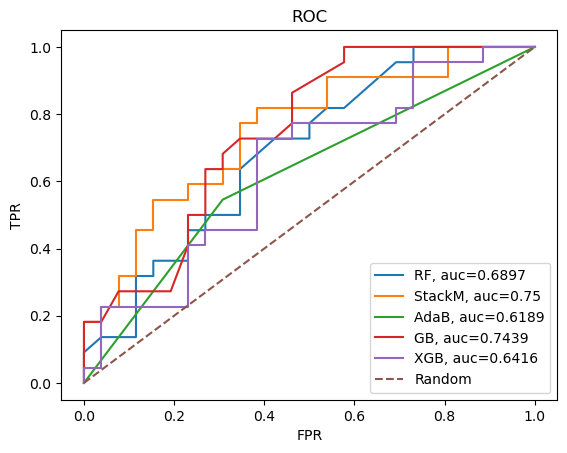

In [36]:
# predicted probabilities generated by models
y_pred_probaStack = stackingCLF.predict_proba(X_test)  # stacking
y_pred_probaRF = bagmodel_tuned.predict_proba(X_test)  # RF
y_pred_probaAdB = AdaBoost_tuned.predict_proba(X_test)  # AdaBoost
y_pred_probaGb = GB_tuned.predict_proba(X_test)  # `GradBoost`
y_pred_probaXGB = XGB_tuned.predict_proba(X_test)  # XGBoost

# Stacking ROC dependencies
fpr, tpr, _ = roc_curve(y_test, y_pred_probaStack[:, 1])
auc = round(roc_auc_score(y_test, y_pred_probaStack[:, 1]), 4)

# RF ROC dependencies
fpr_RF, tpr_RF, _ = roc_curve(y_test, y_pred_probaRF[:, 1])
auc_RF = round(roc_auc_score(y_test, y_pred_probaRF[:, 1]), 4)

# AdaBoost ROC dependencies
fpr_AB, tpr_AB, _ = roc_curve(y_test, y_pred_probaAdB[:, 1])
auc_AB = round(roc_auc_score(y_test, y_pred_probaAdB[:, 1]), 4)

# Gradient Boost ROC dependencies
fpr_GB, tpr_GB, _ = roc_curve(y_test, y_pred_probaGb[:, 1])
auc_GB = round(roc_auc_score(y_test, y_pred_probaGb[:, 1]), 4)

# XGB ROC dependencies
fpr_XGB, tpr_XGB, _ = roc_curve(y_test, y_pred_probaXGB[:, 1])
auc_XGB = round(roc_auc_score(y_test, y_pred_probaXGB[:, 1]), 4)

# RF Model
plt.plot(fpr_RF, tpr_RF, label="RF, auc=" + str(auc_RF))
# Stacking Model
plt.plot(fpr, tpr, label="StackM, auc=" + str(auc))
# AdaBoost Model
plt.plot(fpr_AB, tpr_AB, label="AdaB, auc=" + str(auc_AB))
# `GradBoost` Model
plt.plot(fpr_GB, tpr_GB, label="GB, auc=" + str(auc_GB))
# XGBoost Model
plt.plot(fpr_XGB, tpr_XGB, label="XGB, auc=" + str(auc_XGB))

# Random guess model
plt.plot(fpr, fpr, "--", label="Random")
plt.title("ROC")
plt.ylabel("TPR")
plt.xlabel("FPR")

plt.legend(loc=4)
plt.show()

Tốt! Mọi mô hình đều hoạt động khá tốt, một số mô hình vượt AUC 70%. Cần nhớ rằng ta chưa khám phá hết các siêu tham số của các mô hình, nhưng đây là điểm khởi đầu đủ tốt để bạn tạo mô hình của riêng mình và khám phá không gian siêu tham số cùng ảnh hưởng của nó lên hiệu suất mô hình.

## **3. Kết luận**

Bài này khám phá thuật toán học tập kết hợp cuối cùng, là gradient boosting, chi tiết hơn sau khi nhắc ngắn gọn ở Module 3. Ta đã so sánh mọi thuật toán học tập kết hợp trong module này trên một bài toán phân loại chung và thu được kết quả tốt hơn đáng kể so với mô hình không có kỹ năng, qua đó cho thấy giá trị tăng thêm khi dùng sức dự báo kết hợp của các bộ học yếu.

**Tài liệu tham khảo**

1. Murphy, Kevin P. *Probabilistic Machine Learning: An Introduction.* MIT Press, 2022.
2. University of California, Irvine Machine Learning Repository. "Real Estate Valuation Data Set." https://archive.ics.uci.edu/ml/datasets/Real+estate+valuation+data+set